# temperature (meteo) : extraction et prevision

In [142]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import periodogram
from statsmodels.tsa.stattools import acf
from statsmodels.tsa.tsatools import detrend
from statsmodels.tsa.seasonal import MSTL

import sys
sys.path.append("..")
from adapt_utils import sliding_window, predict, courbe_apprentissage, courbe_melange, comparer_adapt, barres_adapt

In [143]:
city = "Vancouver"

df = pd.read_csv("../../data/meteo/temperature.csv", parse_dates=["datetime"])
serie = df.set_index("datetime")[city] - 273.15
serie = serie.interpolate(limit_area="inside").dropna().loc[:pd.Timestamp("2017-10-28 00:00")]

temp = serie.to_numpy()
print(len(temp), "points de", serie.index[0], "a", serie.index[-1])
print("min/moy/max :", round(temp.min(), 1), round(temp.mean(), 1), round(temp.max(), 1))

44460 points de 2012-10-01 13:00:00 a 2017-10-28 00:00:00
min/moy/max : -28.0 10.7 33.9


## 1. visualisation

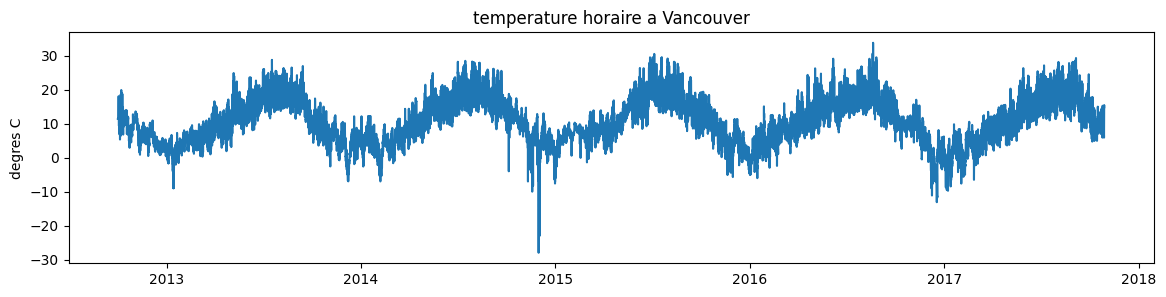

In [144]:
plt.figure(figsize=(14, 3))
plt.plot(serie)
plt.title(f"temperature horaire a {city}")
plt.ylabel("degres C")
plt.show()

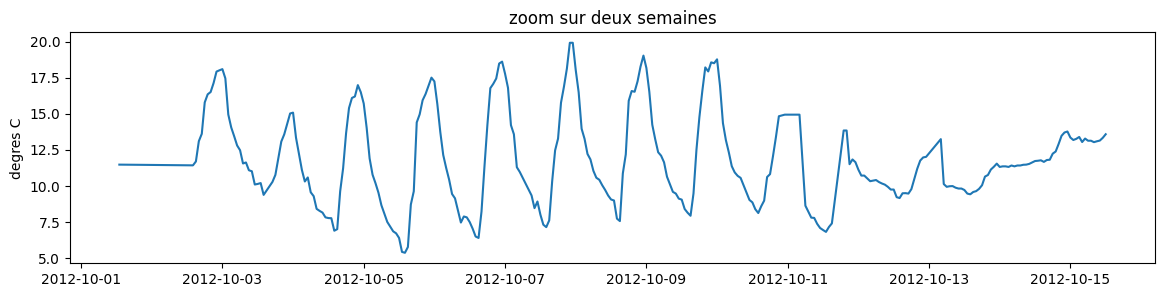

In [145]:
plt.figure(figsize=(14, 3))
plt.plot(serie.iloc[:24 * 14])
plt.title("zoom sur deux semaines")
plt.ylabel("degres C")
plt.show()

## 2. tendance (detrend)

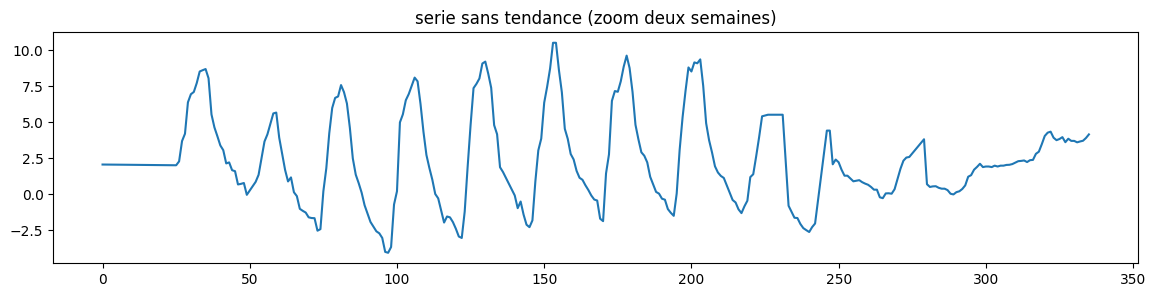

In [146]:
temp_sans_tendance = detrend(temp, order=1)

plt.figure(figsize=(14, 3))
plt.plot(temp_sans_tendance[:24 * 14])
plt.title("serie sans tendance (zoom deux semaines)")
plt.show()

## 3. periode (ACF)

on calcule l'ACF sur le signal detendance

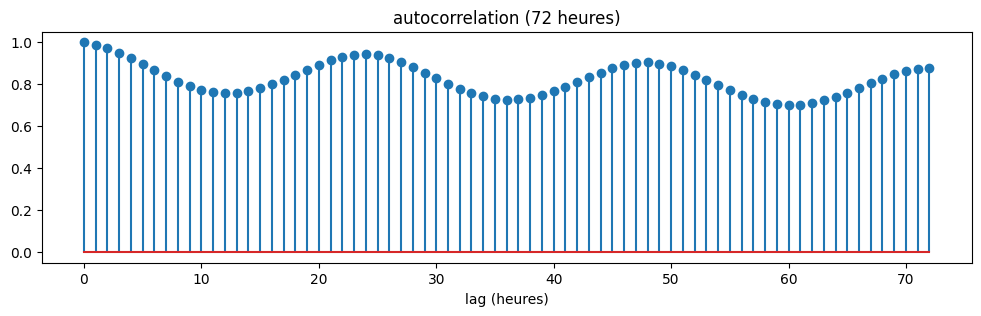

In [147]:
acf_values = acf(temp_sans_tendance, nlags=72)

plt.figure(figsize=(12, 3))
plt.stem(acf_values)
plt.title("autocorrelation (72 heures)")
plt.xlabel("lag (heures)")
plt.show()

## 4. periodogramme

In [148]:
f, power = periodogram(temp_sans_tendance)
periodes = 1 / f[1:]
puissance = power[1:]

ordre = np.argsort(puissance)[::-1]
periodes_detectees = []
for i in ordre:
    p = periodes[i]
    if all(not (0.6 < p / autre < 1.6) for autre in periodes_detectees):
        periodes_detectees.append(p)
    if len(periodes_detectees) == 2:
        break
periodes_detectees = sorted(int(round(p)) for p in periodes_detectees)
print("periodes detectees :", periodes_detectees, "heures")

periodes detectees : [24, 8892] heures


## 5. extraction (STL)

In [149]:
from series_utils import estimate_period

from scipy.signal import find_peaks
from statsmodels.tsa.seasonal import STL

#affichage de la période, de la pente, de l'amplitude et du bruit
period = estimate_period(temp)
res = STL(temp, period=period, robust=True).fit()
pente=np.polyfit(np.arange(len(temp)), res.trend, 1)[0]
amplitude = (res.seasonal.max() - res.seasonal.min()) / 2
bruit = np.nanstd(res.resid)
print(f"periode : {period} heures, pente : {pente:.3f}, amplitude : {amplitude:.3f}, bruit : {bruit:.3f}")

periode : 24 heures, pente : 0.000, amplitude : 15.173, bruit : 1.229


## 6. extraction rapide : cycle journalier (STL)


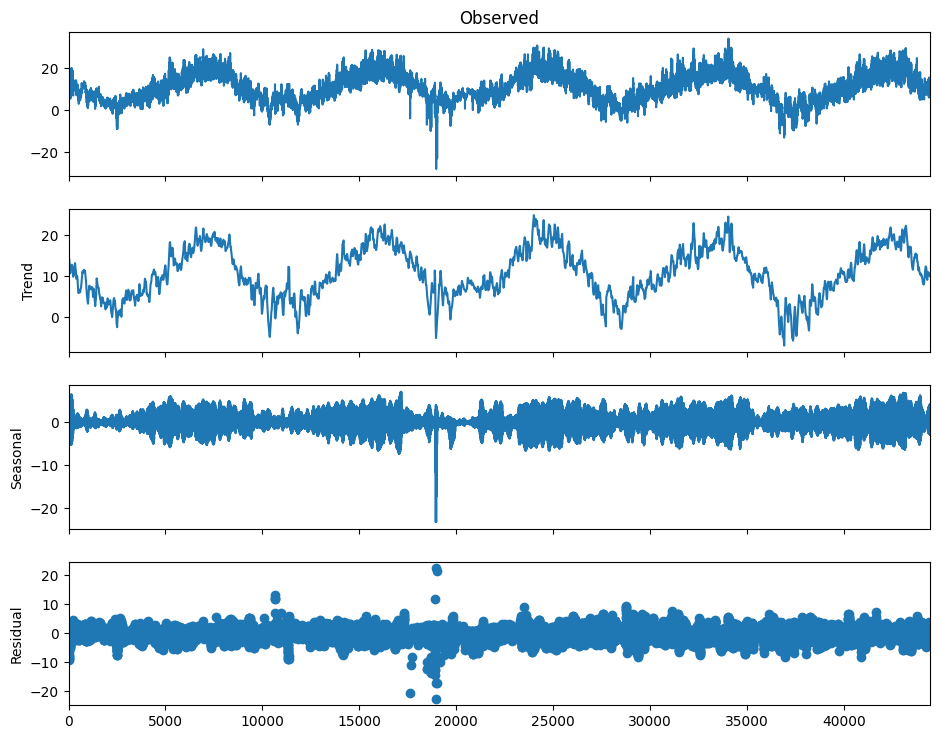

In [150]:
periode_jour = periodes_detectees[0]
res_stl = STL(temp, period=periode_jour, robust=True).fit()

fig = res_stl.plot()
fig.set_size_inches(10, 8)
plt.show()

## 7. prevision : villes source vers ville cible

In [151]:
fin_commune = pd.Timestamp("2017-10-28 00:00")

def temperature_ville(ville):
    s = df.set_index("datetime")[ville] - 273.15
    return s.interpolate(limit_area="inside").dropna().loc[:fin_commune].to_numpy()

source_villes = ["Seattle", "Portland", "San Francisco", "Los Angeles"]
ville_cible = "Jerusalem"
window_size = 24
horizon = 24

Xs_train_list, ys_train_list, Xs_test_list, ys_test_list = [], [], [], []
for v in source_villes:
    X, y = sliding_window(temperature_ville(v), window_size, horizon)
    s = int(len(X) * 0.8)
    Xs_train_list.append(X[:s]); ys_train_list.append(y[:s])
    Xs_test_list.append(X[s:]); ys_test_list.append(y[s:])
Xs_train = np.vstack(Xs_train_list); ys_train = np.concatenate(ys_train_list)
Xs_test = np.vstack(Xs_test_list); ys_test = np.concatenate(ys_test_list)

Xc, yc = sliding_window(temperature_ville(ville_cible), window_size, horizon)
split_c = int(len(Xc) * 0.8)
Xc_train, yc_train, Xc_test, yc_test = Xc[:split_c], yc[:split_c], Xc[split_c:], yc[split_c:]

r_source_source = predict("forecast", Xs_train, ys_train, Xs_test, ys_test)
r_source_cible = predict("forecast", Xs_train, ys_train, Xc_test, yc_test)
print("source -> source :", {k: round(v, 3) for k, v in r_source_source.items()})
print("source -> cible  :", {k: round(v, 3) for k, v in r_source_cible.items()})

source -> source : {'mse': 6.58, 'r2': 0.879}
source -> cible  : {'mse': 4.698, 'r2': 0.892}


## 8. combien de donnees cible pour un bon modele

on part du modele entraine sur la source seule, et on ajoute des donnees cible a l'entrainement, en mesurant le R2 sur le test cible.

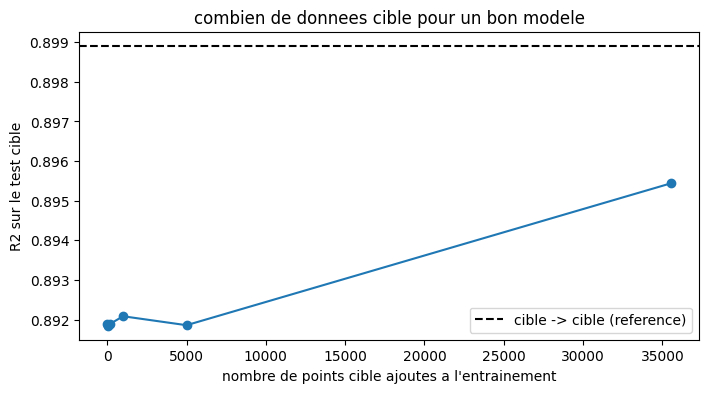

In [152]:
r_cible_ref = predict("forecast", Xc_train, yc_train, Xc_test, yc_test)

n_values = [0, 50, 200, 1000, 5000, len(Xc_train)]
r2_courbe = []
for n in n_values:
    if n == 0:
        X_train, y_train = Xs_train, ys_train
    else:
        X_train = np.vstack([Xs_train, Xc_train[:n]])
        y_train = np.concatenate([ys_train, yc_train[:n]])
    r2_courbe.append(predict("forecast", X_train, y_train, Xc_test, yc_test)["r2"])

plt.figure(figsize=(8, 4))
plt.plot(n_values, r2_courbe, marker="o")
plt.axhline(r_cible_ref["r2"], color="k", linestyle="--", label="cible -> cible (reference)")
plt.xlabel("nombre de points cible ajoutes a l'entrainement")
plt.ylabel("R2 sur le test cible")
plt.title("combien de donnees cible pour un bon modele")
plt.legend()
plt.show()

## 9. courbes d'apprentissage separees : serie brute (source et cible)

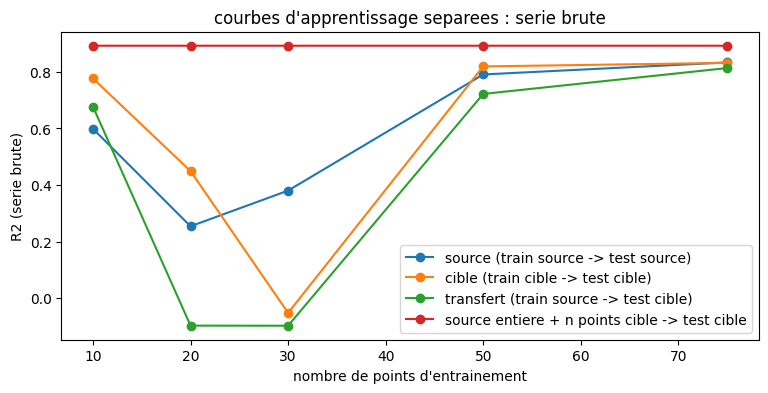

In [153]:
n_values = [10, 20, 30, 50, 75]
ns_source, r2_source = courbe_apprentissage(Xs_train, ys_train, Xs_test, ys_test, "forecast", n_values)
ns_cible, r2_cible = courbe_apprentissage(Xc_train, yc_train, Xc_test, yc_test, "forecast", n_values)

ns_transfert, r2_transfert = courbe_apprentissage(Xs_train, ys_train, Xc_test, yc_test, "forecast", n_values)

ns_melange, r2_melange = courbe_melange(Xs_train, ys_train, Xc_train, yc_train, Xc_test, yc_test, "forecast", n_values)

plt.figure(figsize=(9, 4))
plt.plot(ns_source, r2_source, marker="o", label="source (train source -> test source)")
plt.plot(ns_cible, r2_cible, marker="o", label="cible (train cible -> test cible)")
plt.plot(ns_transfert, r2_transfert, marker="o", label="transfert (train source -> test cible)")
plt.plot(ns_melange, r2_melange, marker="o", label="source entiere + n points cible -> test cible")
plt.xlabel("nombre de points d'entrainement")
plt.ylabel("R2 (serie brute)")
plt.title("courbes d'apprentissage separees : serie brute")
plt.legend()
plt.show()

## 10. prevision de la serie desaisonnalisee (T+N, MSTL)

In [154]:
sigma_bruit = {}
n_annee = 8760

def serie_TN(ville, ratio=0.8):
    temp = temperature_ville(ville)
    n_app = int(len(temp) * ratio)
    res = MSTL(temp[:n_app], periods=(24, 8766), stl_kwargs=dict(seasonal_jump=24, trend_jump=24, low_pass_jump=24)).fit()
    sigma_bruit[ville] = np.nanstd(res.resid)
    sais_app = np.asarray(res.seasonal).sum(axis=1)
    n_test = len(temp) - n_app
    n_blocs = n_app // n_annee
    blocs = np.stack([sais_app[n_app - (k + 1) * n_annee: n_app - k * n_annee] for k in range(n_blocs)])
    prolonge = np.tile(blocs.mean(axis=0), n_test // n_annee + 1)[:n_test]
    return temp - np.concatenate([sais_app, prolonge])

horizon_residu = 24

series_TN = {}
Xrs_tr_list, yrs_tr_list, Xrs_te_list, yrs_te_list = [], [], [], []
for v in source_villes:
    series_TN[v] = serie_TN(v)
    X, y = sliding_window(series_TN[v], window_size, horizon_residu)
    s = int(len(X) * 0.8)
    Xrs_tr_list.append(X[:s]); yrs_tr_list.append(y[:s])
    Xrs_te_list.append(X[s:]); yrs_te_list.append(y[s:])
Xrs_train = np.vstack(Xrs_tr_list); yrs_train = np.concatenate(yrs_tr_list)
Xrs_test = np.vstack(Xrs_te_list); yrs_test = np.concatenate(yrs_te_list)

series_TN[ville_cible] = serie_TN(ville_cible)
Xrc, yrc = sliding_window(series_TN[ville_cible], window_size, horizon_residu)
split_rc = int(len(Xrc) * 0.8)
Xrc_train, yrc_train, Xrc_test, yrc_test = Xrc[:split_rc], yrc[:split_rc], Xrc[split_rc:], yrc[split_rc:]

r_res_ss = predict("forecast", Xrs_train, yrs_train, Xrs_test, yrs_test)
r_res_sc = predict("forecast", Xrs_train, yrs_train, Xrc_test, yrc_test)
print("T+N source -> source :", {k: round(v, 3) for k, v in r_res_ss.items()})
print("T+N source -> cible  :", {k: round(v, 3) for k, v in r_res_sc.items()})

T+N source -> source : {'mse': 7.485, 'r2': 0.656}
T+N source -> cible  : {'mse': 6.034, 'r2': 0.361}


## 11. serie desaisonnalisee (T+N) : combien de donnees cible pour un bon modele


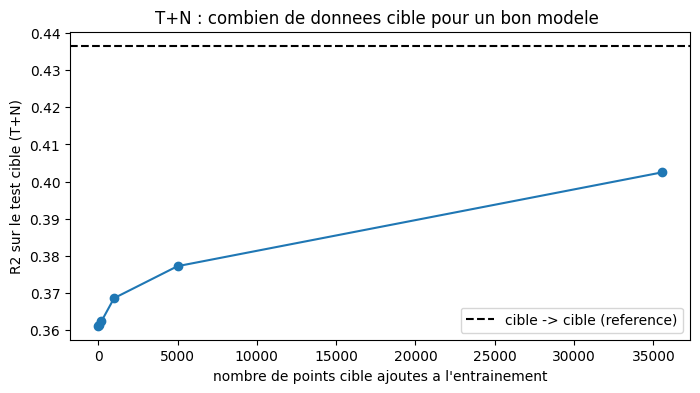

In [155]:
r_res_ref = predict("forecast", Xrc_train, yrc_train, Xrc_test, yrc_test)

n_values_r = [0, 50, 200, 1000, 5000, len(Xrc_train)]
r2_courbe_r = []
for n in n_values_r:
    if n == 0:
        X_train, y_train = Xrs_train, yrs_train
    else:
        X_train = np.vstack([Xrs_train, Xrc_train[:n]])
        y_train = np.concatenate([yrs_train, yrc_train[:n]])
    r2_courbe_r.append(predict("forecast", X_train, y_train, Xrc_test, yrc_test)["r2"])

plt.figure(figsize=(8, 4))
plt.plot(n_values_r, r2_courbe_r, marker="o")
plt.axhline(r_res_ref["r2"], color="k", linestyle="--", label="cible -> cible (reference)")
plt.xlabel("nombre de points cible ajoutes a l'entrainement")
plt.ylabel("R2 sur le test cible (T+N)")
plt.title("T+N : combien de donnees cible pour un bon modele ")
plt.legend()
plt.show()

## 12. courbes d'apprentissage separees : T+N (source et cible)


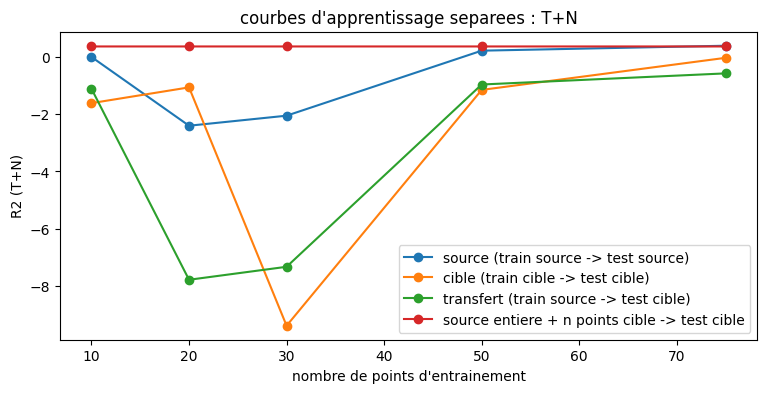

In [156]:
ns_source, r2_source = courbe_apprentissage(Xrs_train, yrs_train, Xrs_test, yrs_test, "forecast", n_values)
ns_cible, r2_cible = courbe_apprentissage(Xrc_train, yrc_train, Xrc_test, yrc_test, "forecast", n_values)

ns_transfert, r2_transfert = courbe_apprentissage(Xrs_train, yrs_train, Xrc_test, yrc_test, "forecast", n_values)

ns_melange, r2_melange = courbe_melange(Xrs_train, yrs_train, Xrc_train, yrc_train, Xrc_test, yrc_test, "forecast", n_values)

plt.figure(figsize=(9, 4))
plt.plot(ns_source, r2_source, marker="o", label="source (train source -> test source)")
plt.plot(ns_cible, r2_cible, marker="o", label="cible (train cible -> test cible)")
plt.plot(ns_transfert, r2_transfert, marker="o", label="transfert (train source -> test cible)")
plt.plot(ns_melange, r2_melange, marker="o", label="source entiere + n points cible -> test cible")
plt.xlabel("nombre de points d'entrainement")
plt.ylabel("R2 (T+N)")
plt.title("courbes d'apprentissage separees : T+N")
plt.legend()
plt.show()

## 13. performances par ville source

deux facons de mesurer la performance par ville. d'abord un seul modele partage, entraine sur toutes les villes source a la fois puis evalue ville par ville : cela mesure ce que vaut un modele commun. ensuite un modele propre a chaque ville, entraine et teste sur la meme ville seule.

temperature brute (modele partage) : R2 par ville source
  Seattle : 0.863
  Portland : 0.865
  San Francisco : 0.834
  Los Angeles : 0.85
cible (Jerusalem) : 0.892


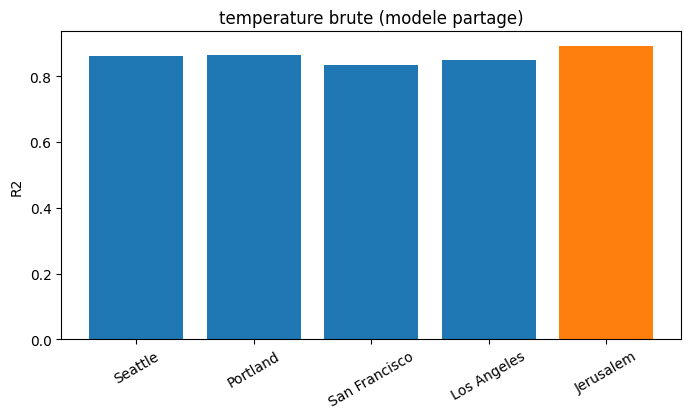

In [157]:
def barres_par_ville(X_train, y_train, test_X_list, test_y_list, X_cible, y_cible, titre):
    valeurs = []
    print(titre, ": R2 par ville source")
    for k, ville in enumerate(source_villes):
        r2 = predict("forecast", X_train, y_train, test_X_list[k], test_y_list[k])["r2"]
        valeurs.append(r2)
        print(f"  {ville} : {round(r2, 3)}")
    r2_cible = predict("forecast", X_train, y_train, X_cible, y_cible)["r2"]
    print(f"cible ({ville_cible}) : {round(r2_cible, 3)}")

    noms = source_villes + [ville_cible]
    couleurs = ["tab:blue"] * len(source_villes) + ["tab:orange"]
    plt.figure(figsize=(8, 4))
    plt.bar(noms, valeurs + [r2_cible], color=couleurs)
    plt.ylabel("R2")
    plt.title(titre)
    plt.xticks(rotation=30)
    plt.show()

barres_par_ville(Xs_train, ys_train, Xs_test_list, ys_test_list, Xc_test, yc_test, "temperature brute (modele partage)")

serie T+N (modele partage) : R2 par ville source
  Seattle : 0.401
  Portland : 0.391
  San Francisco : 0.472
  Los Angeles : 0.497
cible (Jerusalem) : 0.361


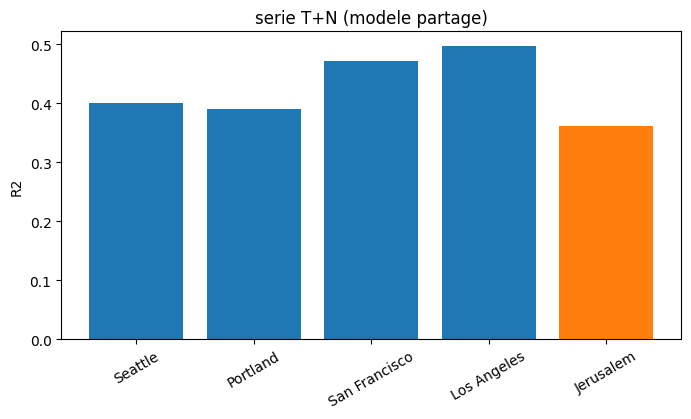

In [158]:
barres_par_ville(Xrs_train, yrs_train, Xrs_te_list, yrs_te_list, Xrc_test, yrc_test, "serie T+N (modele partage)")

temperature brute (un modele par ville) : R2 par ville (un modele par ville)
  Seattle : 0.864
  Portland : 0.865
  San Francisco : 0.834
  Los Angeles : 0.854
cible (Jerusalem) : 0.899


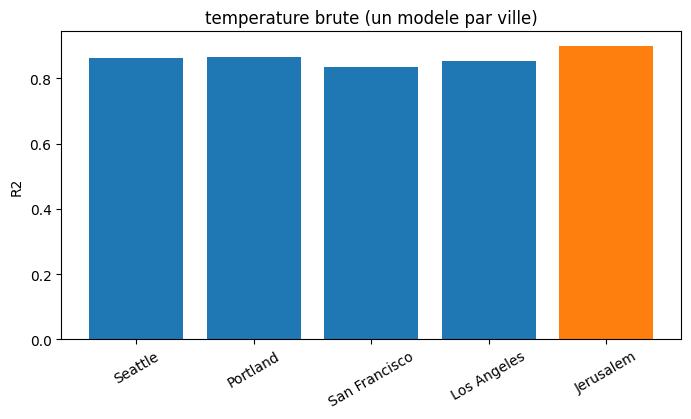

In [159]:
def barres_par_ville_propre(train_X, train_y, test_X, test_y, Xc_tr, yc_tr, Xc_te, yc_te, titre):
    valeurs = []
    print(titre, ": R2 par ville (un modele par ville)")
    for k, ville in enumerate(source_villes):
        r2 = predict("forecast", train_X[k], train_y[k], test_X[k], test_y[k])["r2"]
        valeurs.append(r2)
        print(f"  {ville} : {round(r2, 3)}")
    r2_cible = predict("forecast", Xc_tr, yc_tr, Xc_te, yc_te)["r2"]
    print(f"cible ({ville_cible}) : {round(r2_cible, 3)}")

    noms = source_villes + [ville_cible]
    couleurs = ["tab:blue"] * len(source_villes) + ["tab:orange"]
    plt.figure(figsize=(8, 4))
    plt.bar(noms, valeurs + [r2_cible], color=couleurs)
    plt.ylabel("R2")
    plt.title(titre)
    plt.xticks(rotation=30)
    plt.show()

barres_par_ville_propre(Xs_train_list, ys_train_list, Xs_test_list, ys_test_list, Xc_train, yc_train, Xc_test, yc_test, "temperature brute (un modele par ville)")

serie T+N (un modele par ville) : R2 par ville (un modele par ville)
  Seattle : 0.445


  Portland : 0.432
  San Francisco : 0.491
  Los Angeles : 0.534
cible (Jerusalem) : 0.437


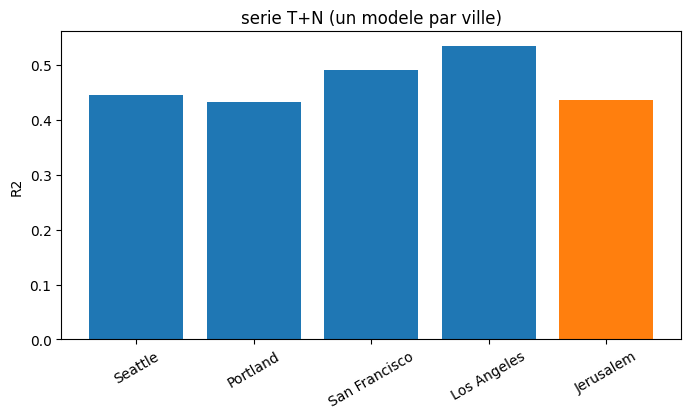

In [160]:
barres_par_ville_propre(Xrs_tr_list, yrs_tr_list, Xrs_te_list, yrs_te_list, Xrc_train, yrc_train, Xrc_test, yrc_test, "serie T+N (un modele par ville)")

## 14. normalisation par le bruit

le R2 par ville depend de la variance totale du domaine, qui differe (Jerusalem varie peu, donc son R2 s'effondre). pour comparer equitablement les villes, on rapporte l'erreur au niveau de bruit propre a chaque domaine : RMSE / sigma.

RMSE / sigma_bruit par ville (T+N) :
  Seattle : 1.22
  Portland : 1.15
  San Francisco : 1.25
  Los Angeles : 1.07
  cible (Jerusalem) : 1.1


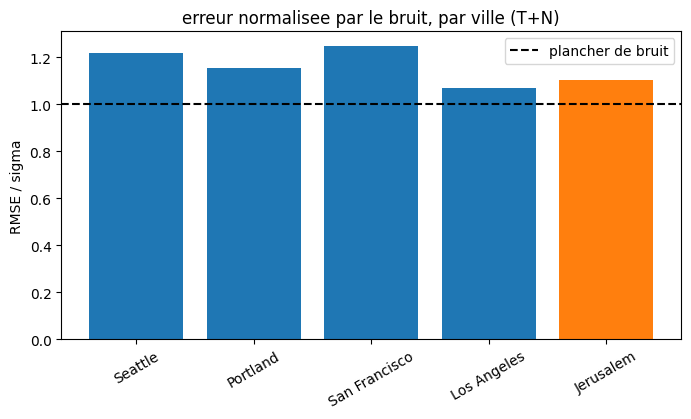

In [161]:
normes = []
print("RMSE / sigma_bruit par ville (T+N) :")
for k, ville in enumerate(source_villes):
    mse = predict("forecast", Xrs_train, yrs_train, Xrs_te_list[k], yrs_te_list[k])["mse"]
    n = np.sqrt(mse) / sigma_bruit[ville]
    normes.append(n)
    print(f"  {ville} : {round(n, 2)}")
mse_cible = predict("forecast", Xrs_train, yrs_train, Xrc_test, yrc_test)["mse"]
norme_cible = np.sqrt(mse_cible) / sigma_bruit[ville_cible]
print(f"  cible ({ville_cible}) : {round(norme_cible, 2)}")

noms = source_villes + [ville_cible]
couleurs = ["tab:blue"] * len(source_villes) + ["tab:orange"]
plt.figure(figsize=(8, 4))
plt.bar(noms, normes + [norme_cible], color=couleurs)
plt.axhline(1.0, color="k", linestyle="--", label="plancher de bruit")
plt.ylabel("RMSE / sigma")
plt.title("erreur normalisee par le bruit, par ville (T+N)")
plt.xticks(rotation=30)
plt.legend()
plt.show()

## 15. normalisation par le bruit : un modele par ville

RMSE / sigma_bruit par ville (T+N, un modele par ville) :
  Seattle : 1.17
  Portland : 1.12
  San Francisco : 1.23
  Los Angeles : 1.03
  cible (Jerusalem) : 1.04


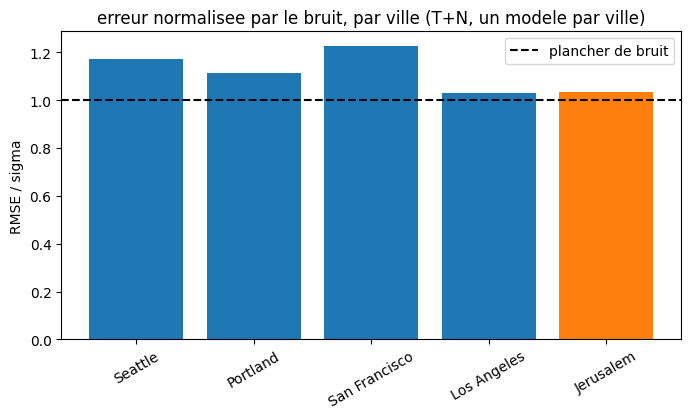

In [162]:
normes_propre = []
print("RMSE / sigma_bruit par ville (T+N, un modele par ville) :")
for k, ville in enumerate(source_villes):
    mse = predict("forecast", Xrs_tr_list[k], yrs_tr_list[k], Xrs_te_list[k], yrs_te_list[k])["mse"]
    n = np.sqrt(mse) / sigma_bruit[ville]
    normes_propre.append(n)
    print(f"  {ville} : {round(n, 2)}")
mse_cible = predict("forecast", Xrc_train, yrc_train, Xrc_test, yrc_test)["mse"]
norme_cible_propre = np.sqrt(mse_cible) / sigma_bruit[ville_cible]
print(f"  cible ({ville_cible}) : {round(norme_cible_propre, 2)}")

noms = source_villes + [ville_cible]
couleurs = ["tab:blue"] * len(source_villes) + ["tab:orange"]
plt.figure(figsize=(8, 4))
plt.bar(noms, normes_propre + [norme_cible_propre], color=couleurs)
plt.axhline(1.0, color="k", linestyle="--", label="plancher de bruit")
plt.ylabel("RMSE / sigma")
plt.title("erreur normalisee par le bruit, par ville (T+N, un modele par ville)")
plt.xticks(rotation=30)
plt.legend()
plt.show()

## 16. ADAPT


feature_based,CORAL

instance_based, KMM

parameter_based,  RegularTransferLR

temperature brute
  sans adaptation                  0.892
  CORAL (feature)                  0.818
  KMM (instance)                   0.894
  RegularTransferLR (parametre)    0.899
  cible -> cible                   0.899


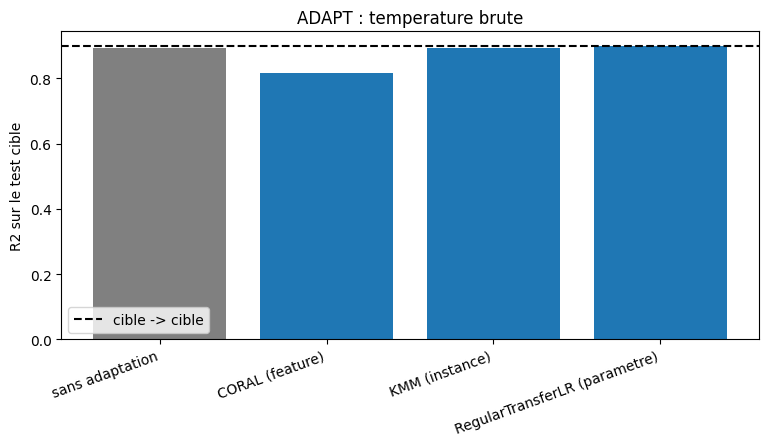

In [163]:
print("temperature brute")
res_adapt_brute = comparer_adapt("forecast", Xs_train, ys_train, Xc_train, yc_train, Xc_test, yc_test)
for k, v in res_adapt_brute.items():
    print(f"  {k:32s} {round(v, 3)}")

barres_adapt(res_adapt_brute, "ADAPT : temperature brute", "R2 sur le test cible")

serie T+N
  sans adaptation                  0.361
  CORAL (feature)                  0.017
  KMM (instance)                   0.367
  RegularTransferLR (parametre)    0.437
  cible -> cible                   0.437


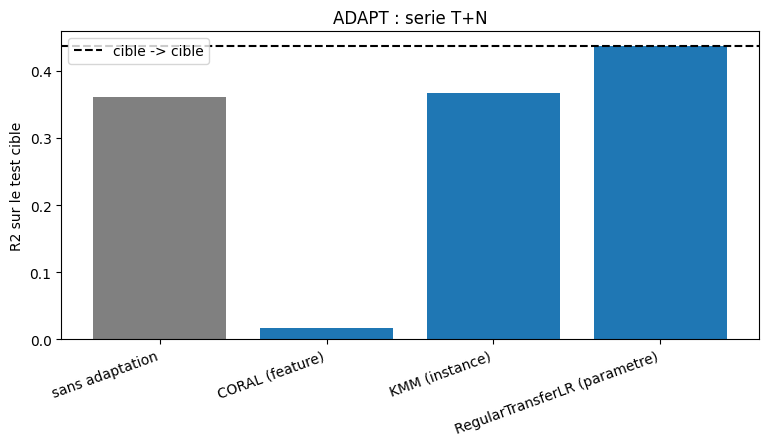

In [164]:
print("serie T+N")
res_adapt_tn = comparer_adapt("forecast", Xrs_train, yrs_train, Xrc_train, yrc_train, Xrc_test, yrc_test)
for k, v in res_adapt_tn.items():
    print(f"  {k:32s} {round(v, 3)}")

barres_adapt(res_adapt_tn, "ADAPT : serie T+N", "R2 sur le test cible")

## 17. adaptation de domaine : erreur normalisee par le bruit

  sans adaptation                  1.104
  CORAL (feature)                  1.369
  KMM (instance)                   1.099
  RegularTransferLR (parametre)    1.036
  cible -> cible                   1.036


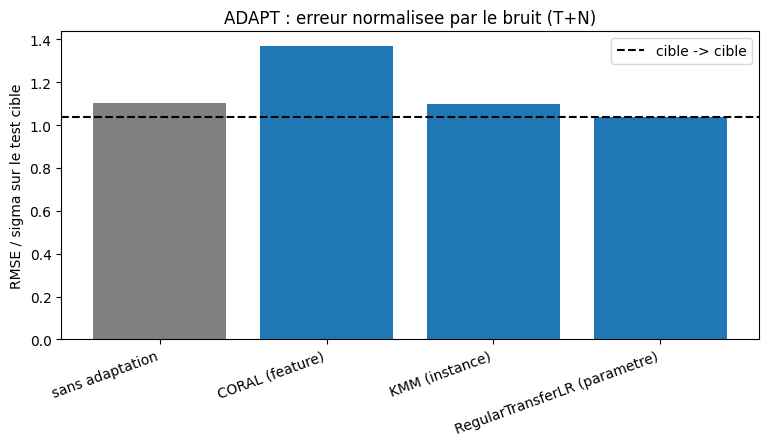

In [165]:
from sklearn.metrics import mean_squared_error

def rmse_sur_sigma(y_vrai, y_pred):
    return float(np.sqrt(mean_squared_error(y_vrai, y_pred)) / sigma_bruit[ville_cible])

res_adapt_norm = comparer_adapt("forecast", Xrs_train, yrs_train, Xrc_train, yrc_train, Xrc_test, yrc_test, score=rmse_sur_sigma)

for k, v in res_adapt_norm.items():
    print(f"  {k:32s} {round(v, 3)}")

barres_adapt(res_adapt_norm, "ADAPT : erreur normalisee par le bruit (T+N)","RMSE / sigma sur le test cible")

## 18. variance de la serie T+N au fil du temps


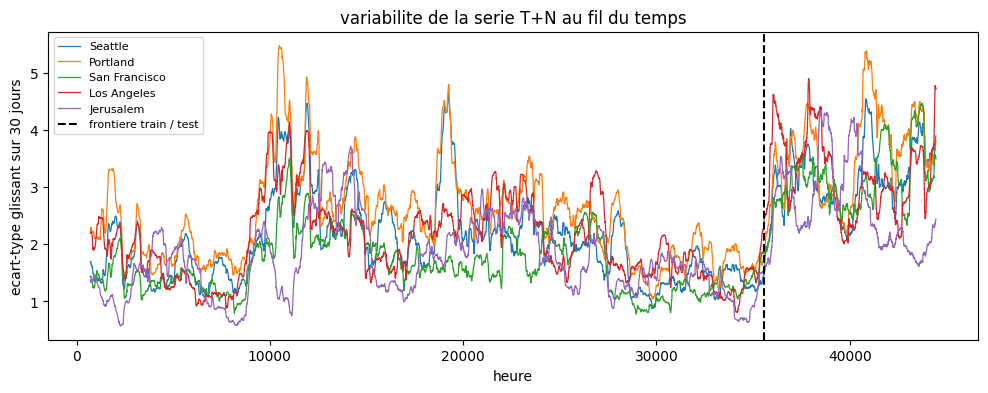

        ville  toute la serie  train  test
      Seattle           2.612  2.314 3.539
     Portland           3.063  2.774 4.014
San Francisco           2.365  1.998 3.401
  Los Angeles           2.873  2.630 3.601
    Jerusalem           3.037  2.988 3.072


In [166]:
fenetre_glissante = 24 * 30

plt.figure(figsize=(12, 4))
lignes = []
for v in source_villes + [ville_cible]:
    z = pd.Series(series_TN[v])
    n_app = int(len(z) * 0.8)
    plt.plot(z.rolling(fenetre_glissante).std(), linewidth=0.9, label=v)
    lignes.append([v, round(float(z.std()), 3), round(float(z[:n_app].std()), 3),
                   round(float(z[n_app:].std()), 3)])

plt.axvline(n_app, color="k", linestyle="--", label="frontiere train / test")
plt.xlabel("heure")
plt.ylabel("ecart-type glissant sur 30 jours")
plt.title("variabilite de la serie T+N au fil du temps")
plt.legend(fontsize=8)
plt.show()

print(pd.DataFrame(lignes, columns=["ville", "toute la serie", "train", "test"]).to_string(index=False))

## 19. le meme graphique avec la MSTL qui voit tout


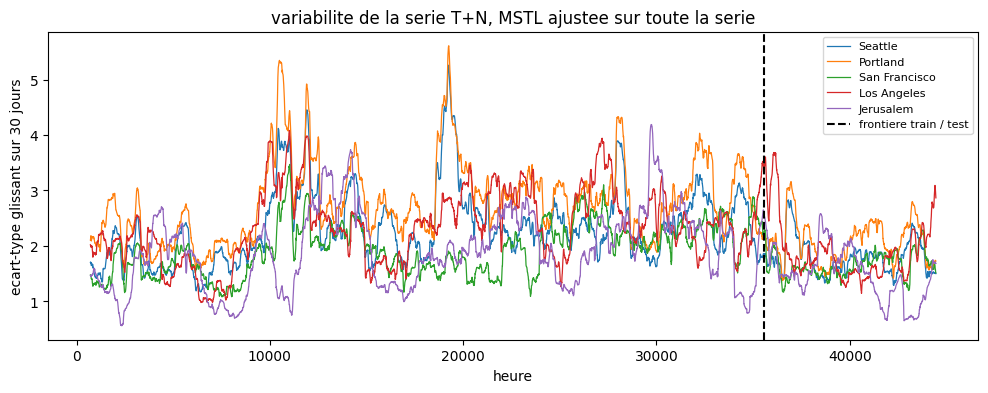

        ville  toute la serie  train  test
      Seattle           2.541  2.648 2.011
     Portland           2.995  3.143 2.309
San Francisco           2.211  2.286 1.777
  Los Angeles           2.830  2.944 2.194
    Jerusalem           2.972  3.183 1.645


In [167]:
series_TN_fuite = {}
for v in source_villes + [ville_cible]:
    temp = temperature_ville(v)
    res = MSTL(temp, periods=(24, 8766),
               stl_kwargs=dict(seasonal_jump=24, trend_jump=24, low_pass_jump=24)).fit()
    series_TN_fuite[v] = temp - np.asarray(res.seasonal).sum(axis=1)

plt.figure(figsize=(12, 4))
lignes_fuite = []
for v in source_villes + [ville_cible]:
    z = pd.Series(series_TN_fuite[v])
    n_app = int(len(z) * 0.8)
    plt.plot(z.rolling(fenetre_glissante).std(), linewidth=0.9, label=v)
    lignes_fuite.append([v, round(float(z.std()), 3), round(float(z[:n_app].std()), 3),
                         round(float(z[n_app:].std()), 3)])

plt.axvline(n_app, color="k", linestyle="--", label="frontiere train / test")
plt.xlabel("heure")
plt.ylabel("ecart-type glissant sur 30 jours")
plt.title("variabilite de la serie T+N, MSTL ajustee sur toute la serie")
plt.legend(fontsize=8)
plt.show()

print(pd.DataFrame(lignes_fuite, columns=["ville", "toute la serie", "train", "test"]).to_string(index=False))

## 20. le prolongement de la saisonnalite

serie_TN prolonge la saisonnalite du test en moyennant les quatre annees completes du train

les colonnes err mesurent l'ecart moyen entre la saisonnalite fabriquee et la reference.

        ville  err derniere  err moyenne  T+N derniere  T+N moyenne  T+N avec fuite
      Seattle          2.24         1.92          4.38         3.54            2.01
     Portland          2.60         2.20          5.02         4.01            2.31
San Francisco          2.19         1.94          4.00         3.40            1.78
  Los Angeles          2.46         2.16          4.64         3.60            2.19
    Jerusalem          1.77         2.06          3.41         3.07            1.64


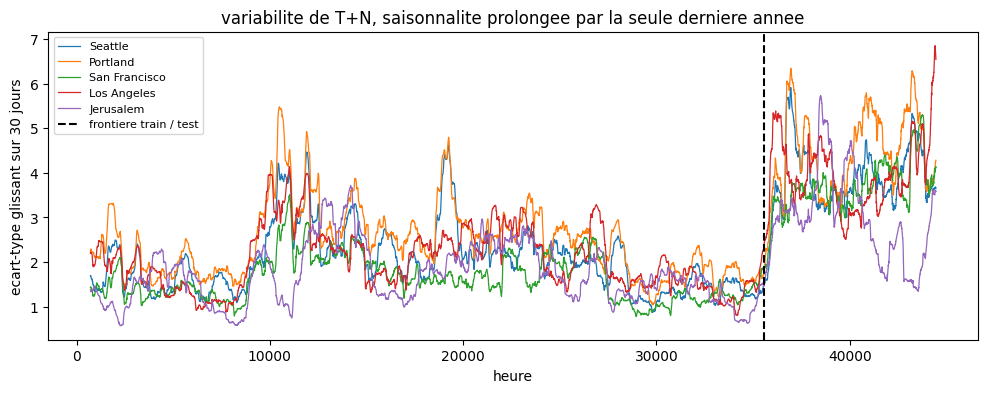

In [168]:
lignes_moy = []
series_TN_derniere = {}
for v in source_villes + [ville_cible]:
    temp = temperature_ville(v)
    n_app = int(len(temp) * 0.8)
    n_test = len(temp) - n_app

    sais_app = temp[:n_app] - series_TN[v][:n_app]
    derniere = np.tile(sais_app[-n_annee:], n_test // n_annee + 1)[:n_test]
    moyenne = temp[n_app:] - series_TN[v][n_app:]
    sais_fuite = temp[n_app:] - series_TN_fuite[v][n_app:]

    series_TN_derniere[v] = np.concatenate([series_TN[v][:n_app], temp[n_app:] - derniere])

    lignes_moy.append([v,
                       round(float(np.mean(np.abs(derniere - sais_fuite))), 2),
                       round(float(np.mean(np.abs(moyenne - sais_fuite))), 2),
                       round(float(np.std(series_TN_derniere[v][n_app:])), 2),
                       round(float(np.std(series_TN[v][n_app:])), 2),
                       round(float(np.std(series_TN_fuite[v][n_app:])), 2)])

print(pd.DataFrame(lignes_moy, columns=["ville", "err derniere", "err moyenne",
                                        "T+N derniere", "T+N moyenne", "T+N avec fuite"]).to_string(index=False))

plt.figure(figsize=(12, 4))
for v in source_villes + [ville_cible]:
    z = pd.Series(series_TN_derniere[v])
    n_app = int(len(z) * 0.8)
    plt.plot(z.rolling(fenetre_glissante).std(), linewidth=0.9, label=v)
plt.axvline(n_app, color="k", linestyle="--", label="frontiere train / test")
plt.xlabel("heure")
plt.ylabel("ecart-type glissant sur 30 jours")
plt.title("variabilite de T+N, saisonnalite prolongee par la seule derniere annee")
plt.legend(fontsize=8)
plt.show()

## 21. miami


    cible  R2 transfert  RMSE/sigma transfert  RMSE/sigma modele cible  RMSE/std(y) transfert
Jerusalem         0.361                 1.104                    1.036                  0.799
    Miami        -0.058                 1.473                    1.193                  1.028


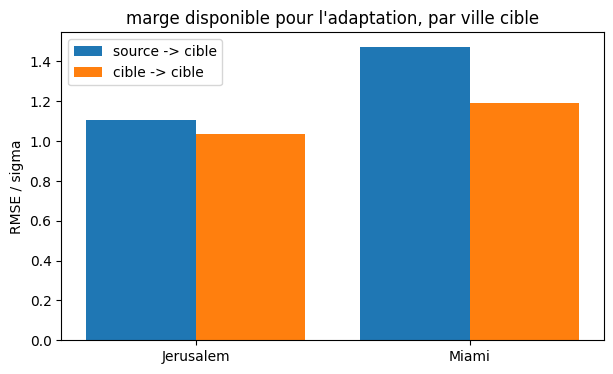

In [169]:
villes_cibles = [ville_cible, "Miami"]

lignes_cibles = []
for v in villes_cibles:
    if v not in series_TN:
        series_TN[v] = serie_TN(v)
    X, y = sliding_window(series_TN[v], window_size, horizon_residu)
    s = int(len(X) * 0.8)
    transfert = predict("forecast", Xrs_train, yrs_train, X[s:], y[s:])
    propre = predict("forecast", X[:s], y[:s], X[s:], y[s:])
    lignes_cibles.append([v,
                          round(transfert["r2"], 3),
                          round(float(np.sqrt(transfert["mse"]) / sigma_bruit[v]), 3),
                          round(float(np.sqrt(propre["mse"]) / sigma_bruit[v]), 3),
                          round(float(np.sqrt(transfert["mse"]) / np.std(y[s:])), 3)])

tab_cibles = pd.DataFrame(lignes_cibles, columns=["cible", "R2 transfert", "RMSE/sigma transfert",
                                                 "RMSE/sigma modele cible", "RMSE/std(y) transfert"])
print(tab_cibles.to_string(index=False))

pos = np.arange(len(villes_cibles))
plt.figure(figsize=(7, 4))
plt.bar(pos - 0.2, tab_cibles["RMSE/sigma transfert"], 0.4, label="source -> cible")
plt.bar(pos + 0.2, tab_cibles["RMSE/sigma modele cible"], 0.4, label="cible -> cible")
plt.xticks(pos, villes_cibles)
plt.ylabel("RMSE / sigma")
plt.title("marge disponible pour l'adaptation, par ville cible")
plt.legend()
plt.show()

## 22.jerusalem

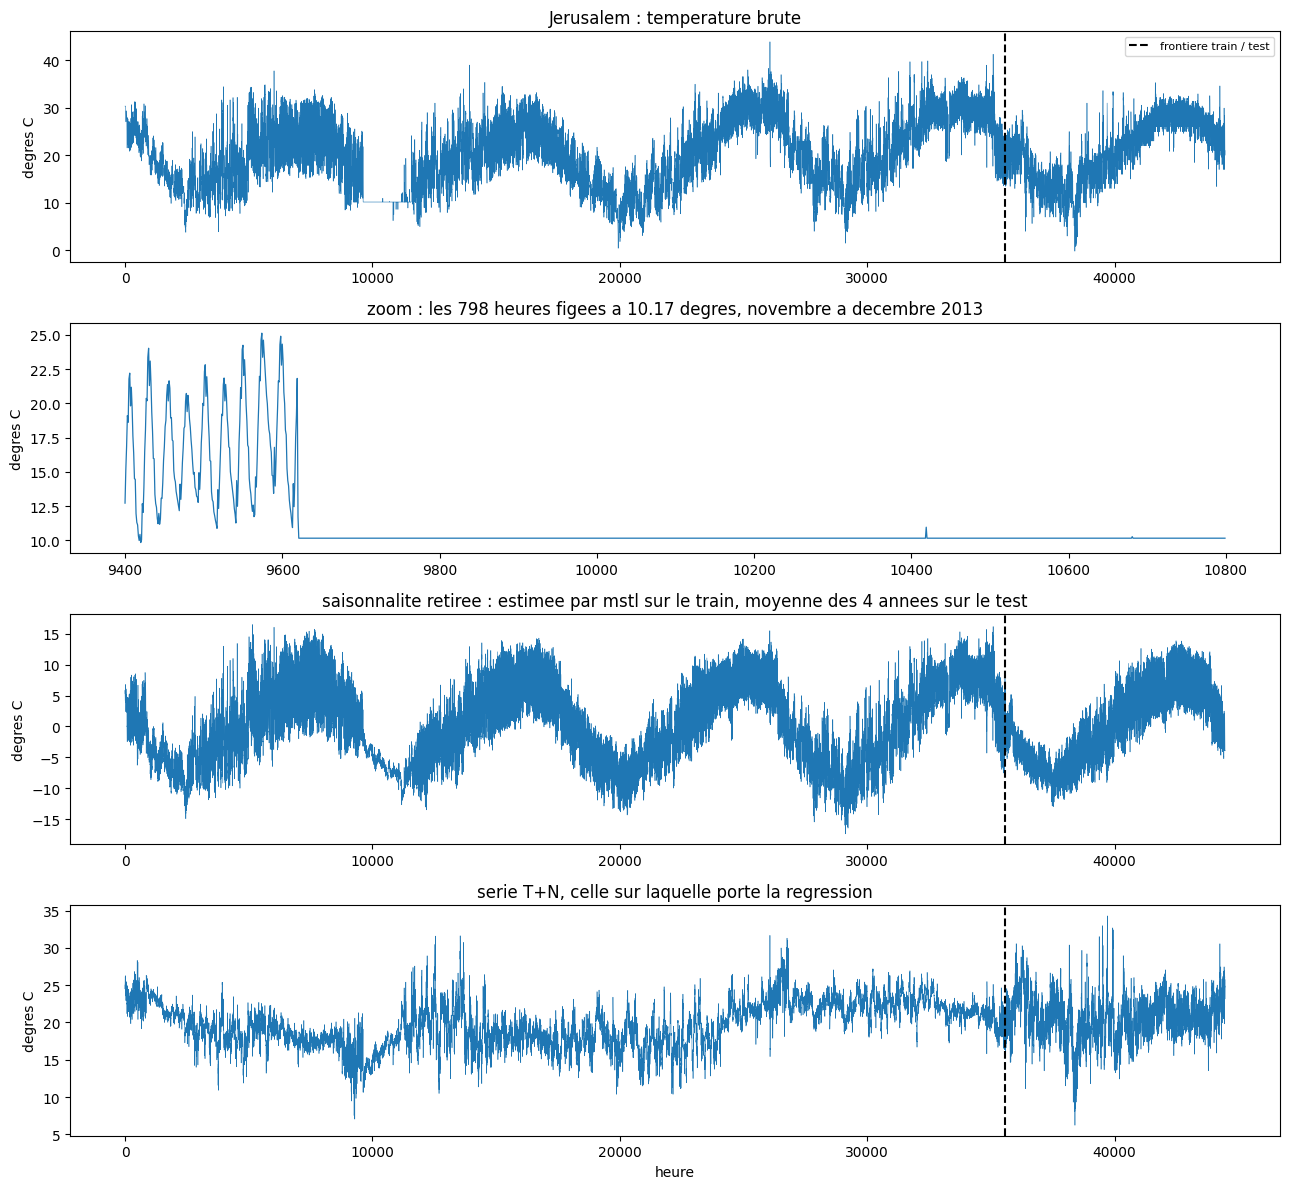

In [170]:
ville_vue = "Jerusalem"

temp_vue = temperature_ville(ville_vue)
n_app_vue = int(len(temp_vue) * 0.8)
res_vue = MSTL(temp_vue[:n_app_vue], periods=(24, 8766), stl_kwargs=dict(seasonal_jump=24, trend_jump=24, low_pass_jump=24)).fit()
sais_vue = np.asarray(res_vue.seasonal).sum(axis=1)
n_test_vue = len(temp_vue) - n_app_vue
n_blocs_vue = n_app_vue // n_annee
blocs_vue = np.stack([sais_vue[n_app_vue - (k + 1) * n_annee: n_app_vue - k * n_annee] for k in range(n_blocs_vue)])
sais_totale = np.concatenate([sais_vue, np.tile(blocs_vue.mean(axis=0), n_test_vue // n_annee + 1)[:n_test_vue]])

fig, ax = plt.subplots(4, 1, figsize=(13, 12))

ax[0].plot(temp_vue, linewidth=0.4)
ax[0].axvline(n_app_vue, color="k", linestyle="--", label="frontiere train / test")
ax[0].set_title(ville_vue + " : temperature brute")
ax[0].set_ylabel("degres C")
ax[0].legend(fontsize=8)

ax[1].plot(range(9400, 10800), temp_vue[9400:10800], linewidth=0.9)
ax[1].set_title("zoom : les 798 heures figees a 10.17 degres, novembre a decembre 2013")
ax[1].set_ylabel("degres C")

ax[2].plot(sais_totale, linewidth=0.4)
ax[2].axvline(n_app_vue, color="k", linestyle="--")
ax[2].set_title("saisonnalite retiree : estimee par mstl sur le train, moyenne des 4 annees sur le test")
ax[2].set_ylabel("degres C")

ax[3].plot(temp_vue - sais_totale, linewidth=0.4)
ax[3].axvline(n_app_vue, color="k", linestyle="--")
ax[3].set_title("serie T+N, celle sur laquelle porte la regression")
ax[3].set_ylabel("degres C")
ax[3].set_xlabel("heure")

plt.tight_layout()
plt.show()